# DỰ ÁN NGHIÊN CỨU DSR301m - ĐẠI HỌC FPT
## ĐỀ TÀI: Phân loại chọn lọc và Hiệu chuẩn xác suất trong Nhận diện Căng thẳng Đáng tin cậy từ Tín hiệu Sinh lý Đeo Cổ tay
**Nhóm tác giả:** Phan Tuấn Đạt, Nguyễn Gia Huy, Trần Lợi Kiều Nhi, Nguyễn Minh Bảo
**Emails:** ptundatwork@gmail.com, huy522006@gmail.com, nhiklt2006@gmail.com, baonguyenminh17@gmail.com

---
### TỔNG QUAN NOTEBOOK THỐNG NHẤT (UNIFIED BENCHMARKING PIPELINE)
Notebook này tích hợp toàn diện hai đóng góp nòng cốt của nhóm:
1. **Dữ liệu đặc trưng y sinh học trích xuất từ Nhi:** `wesad_wrist_features.csv` (5.294 cửa sổ quan sát x 25 đặc trưng từ 4 cảm biến BVP, EDA, TEMP, ACC).
2. **Khung kiểm định LOSO 15-folds chống rò rỉ rãnh kép từ Bảo:** Kết hợp `Outer Leave-One-Subject-Out` và `Inner GroupKFold(3)` gom cụm theo đối tượng nhằm triệt tiêu hoàn toàn rò rỉ dữ liệu giữa các cửa sổ trượt chồng lắp 91.7%.
3. **Hệ thống Benchmark Đa Mô hình Toàn diện (7 Models):**
   - Tuyến tính: Logistic Regression
   - Cây quyết định đơn: Decision Tree (CART)
   - Láng giềng: k-Nearest Neighbors (kNN)
   - Ensemble Bagging: Random Forest
   - Ensemble Boosting: AdaBoost, LightGBM, XGBoost


In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, brier_score_loss
from scipy.stats import wilcoxon

# Các họ mô hình đa dạng phục vụ Benchmark
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
print("[*] Thu vien va moi truong da san sang!")


[*] Thu vien va moi truong da san sang!


### 1. NẠP DỮ LIỆU ĐẶC TRƯNG WESAD (WESAD FEATURE EXTRACTION DATASET)
Đọc file đặc trưng `wesad_wrist_features.csv` bao gồm 15 đối tượng (S2 đến S17).
Xác định ngưỡng vận động mạnh $\theta_{\text{motion}}$ tại phân vị thứ 80 của phương sai gia tốc $\text{Var}(\text{ACC})$.


In [2]:
DATA_PATH = "../Dataset/wesad_wrist_features.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "wesad_wrist_features.csv"

df = pd.read_csv(DATA_PATH)
print(f"[*] Kich thuoc du lieu: {df.shape}")
print(f"[*] 15 doi tuong: {df['subject_id'].unique().tolist()}")
print(f"[*] Phan phoi nhan (0: Khong Stress, 1: Stress):\n{df['label'].value_counts(normalize=True)*100}")

META_COLS = ["subject_id", "time_start_sec", "time_end_sec", "label"]
FEAT_COLS = [c for c in df.columns if c not in META_COLS]
X = df[FEAT_COLS].values
y = df["label"].values
groups = df["subject_id"].values

# Nguong dong hoc P80
THETA_MOTION = np.percentile(df["acc_mag_var"].values, 80)
IS_HIGH_MOTION = (df["acc_mag_var"].values >= THETA_MOTION)
print(f"\n[*] Nguong gia toc theta_motion (P80 Var(ACC)) = {THETA_MOTION:.3f}")
print(f"[*] Ty le cua so van dong manh: {IS_HIGH_MOTION.mean()*100:.2f}%")


[*] Kich thuoc du lieu: (5294, 29)
[*] 15 doi tuong: ['S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'S10', 'S11', 'S13', 'S14', 'S15', 'S16', 'S17']
[*] Phan phoi nhan (0: Khong Stress, 1: Stress):
label
0    64.450321
1    35.549679
Name: proportion, dtype: float64

[*] Nguong gia toc theta_motion (P80 Var(ACC)) = 15.385
[*] Ty le cua so van dong manh: 20.00%


### 2. ĐỊNH NGHĨA CÁC THƯỚC ĐO ĐỘ TIN CẬY (Trustworthy Metrics)
- **Sai số Hiệu chuẩn Kỳ vọng (Expected Calibration Error - ECE):** Đo lường khoảng cách giữa độ tự tin trung bình và độ chính xác thực tế trên $M=10$ phân vùng.
- **Tỷ lệ Báo động Giả khi Vận động ($\text{FAR}_{\text{motion}}$):** Tỷ lệ mẫu Không-Stress có cử động mạnh bị dự đoán nhầm thành Stress trên toàn bộ mẫu Không-Stress vận động.
- **Thước đo Phân loại Chọn lọc:** Độ phủ (Coverage), Selective Macro $F_1$, Selective Stress $F_1$, Selective Accuracy tại ngưỡng tin cậy $\tau$.


In [3]:
def compute_ece(y_true, y_prob, n_bins=10):
    conf = np.maximum(y_prob, 1.0 - y_prob)
    corr = ((y_prob >= 0.5).astype(int) == y_true)
    bin_edges = np.linspace(0.5, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        in_bin = (conf >= bin_edges[i]) & (conf < bin_edges[i+1] if i < n_bins-1 else conf <= bin_edges[i+1])
        if in_bin.sum() > 0:
            prop = in_bin.mean()
            acc_bin = corr[in_bin].mean()
            conf_bin = conf[in_bin].mean()
            ece += prop * abs(acc_bin - conf_bin)
    return ece

def compute_far_motion(y_true, pred_labels, high_motion_mask, accepted_mask=None):
    denominator = ((y_true == 0) & high_motion_mask).sum()
    if denominator == 0:
        return np.nan
    acc = np.ones_like(y_true, dtype=bool) if accepted_mask is None else accepted_mask
    false_alarms = ((pred_labels == 1) & (y_true == 0) & high_motion_mask & acc).sum()
    return (false_alarms / denominator) * 100.0


### 3. HỆ THỐNG ĐA MÔ HÌNH HỌC MÁY BENCHMARK
Thiết lập 7 mô hình thuộc các họ thuật toán kinh điển trong y tế số và khoa học dữ liệu:
1. **Logistic Regression (LR):** Mô hình tuyến tính chuẩn mực, tính toán nhanh.
2. **Decision Tree (DT):** Cây quyết định đơn lẻ (CART), kiểm tra độ nhạy với nhiễu.
3. **k-Nearest Neighbors (kNN):** Phân loại theo khoảng cách (sử dụng trong bài báo gốc Schmidt 2018).
4. **AdaBoost:** Thuật toán tăng cường trọng số cổ điển (Schmidt 2018).
5. **Random Forest (RF):** Thuật toán rừng ngẫu nhiên Bagging (chống nhiễu mạnh).
6. **LightGBM:** Gradient Boosting hiện đại, tối ưu tốc độ và bộ nhớ.
7. **XGBoost:** Gradient Boosting tiên tiến nhất trên dữ liệu bảng sinh lý.


In [4]:
MODELS = {
    'Logistic Regression': lambda: LogisticRegression(max_iter=500, random_state=SEED),
    'Decision Tree': lambda: DecisionTreeClassifier(max_depth=5, random_state=SEED),
    'kNN': lambda: KNeighborsClassifier(n_neighbors=5),
    'AdaBoost': lambda: AdaBoostClassifier(n_estimators=50, random_state=SEED),
    'Random Forest': lambda: RandomForestClassifier(n_estimators=100, max_depth=5, random_state=SEED, n_jobs=-1),
    'LightGBM': lambda: LGBMClassifier(n_estimators=100, max_depth=5, learning_rate=0.08, random_state=SEED, verbose=-1, n_jobs=-1),
    'XGBoost': lambda: XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.08, subsample=0.8, eval_metric='logloss', random_state=SEED, n_jobs=-1)
}


### 4. PIPELINE KIỂM THỬ 15-FOLDS LOSO CHỐNG RÒ RỈ HAI TẦNG (NESTED LEAVE-ONE-SUBJECT-OUT VALIDATION)
- **Outer Split:** 15 folds Leave-One-Subject-Out. Mỗi fold chọn 1 đối tượng làm Test Set, 14 đối tượng làm Train Set.
- **Inner Split (Chống rò rỉ):** Bên trong 14 đối tượng huấn luyện, sử dụng `GroupKFold(n_splits=3)` theo `subject_id` để khớp bộ hiệu chuẩn Isotonic (`CalibratedClassifierCV`). Điều này đảm bảo các cửa sổ chồng lắp 91.7% không bị rò rỉ giữa tập train và tập hiệu chuẩn.


In [5]:
subjects_list = np.unique(groups)
oof_raw_probs = {m: np.zeros(len(df)) for m in MODELS}
oof_cal_probs = {m: np.zeros(len(df)) for m in MODELS}

print(f"=== TIEN HANH CHAY 15-FOLDS LOSO BENCHMARK CHO {len(MODELS)} MO HINH ===")
t_start = time.time()

for sid in subjects_list:
    t_fold = time.time()
    test_idx = (groups == sid)
    train_idx = (groups != sid)
    
    # 1. Chuan hoa StandardScaler doc quyen tren train
    scaler = StandardScaler().fit(X[train_idx])
    X_train = scaler.transform(X[train_idx])
    X_test  = scaler.transform(X[test_idx])
    y_train = y[train_idx]
    g_train = groups[train_idx]
    
    # 2. Tao Inner CV gom cum theo Subject
    inner_cv = list(GroupKFold(n_splits=3).split(X_train, y_train, groups=g_train))
    
    # 3. Fit tung mo hinh (Raw & Isotonic Calibrated)
    for name, init_fn in MODELS.items():
        # Raw
        clf_raw = init_fn().fit(X_train, y_train)
        oof_raw_probs[name][test_idx] = clf_raw.predict_proba(X_test)[:, 1]
        
        # Calibrated
        clf_cal = CalibratedClassifierCV(init_fn(), method="isotonic", cv=inner_cv).fit(X_train, y_train)
        oof_cal_probs[name][test_idx] = clf_cal.predict_proba(X_test)[:, 1]
        
    print(f"Fold {sid:>3} hoan tat ({time.time() - t_fold:4.1f}s)")

print(f"\n[+] Toan bo 15-folds LOSO hoan thanh trong {time.time() - t_start:.1f} giay!")


=== TIEN HANH CHAY 15-FOLDS LOSO BENCHMARK CHO 7 MO HINH ===
Fold S10 hoan tat ( 5.0s)
Fold S11 hoan tat ( 4.8s)
Fold S13 hoan tat ( 5.0s)
Fold S14 hoan tat ( 5.0s)
Fold S15 hoan tat ( 5.3s)
Fold S16 hoan tat ( 4.9s)
Fold S17 hoan tat ( 4.7s)
Fold  S2 hoan tat ( 4.7s)
Fold  S3 hoan tat ( 4.8s)
Fold  S4 hoan tat ( 4.8s)
Fold  S5 hoan tat ( 4.9s)
Fold  S6 hoan tat ( 4.8s)
Fold  S7 hoan tat ( 4.8s)
Fold  S8 hoan tat ( 4.7s)
Fold  S9 hoan tat ( 4.7s)

[+] Toan bo 15-folds LOSO hoan thanh trong 72.8 giay!


### 5. BẢNG TỔNG HỢP HIỆU NĂNG SO SÁNH BENCHMARK ĐA MÔ HÌNH
So sánh toàn diện cả 7 mô hình tại 3 chế độ vận hành:
1. **Full Coverage (Bắt buộc đoán 100%):** Accuracy, Macro F1, Stress F1, ECE, $\text{FAR}_{\text{motion}}$.
2. **Calibrated Coverage (Sau khi hiệu chuẩn Isotonic):** ECE, $\text{FAR}_{\text{motion}}$.
3. **Selective Classification (Tại ngưỡng tối ưu $\tau = 0.80$):** Coverage, Selective Macro F1, Selective Stress F1, Selective ECE, Selective $\text{FAR}_{\text{motion}}$ và Tỷ lệ triệt tiêu báo động giả.


In [6]:
summary_rows = []
tau = 0.80
for name in MODELS:
    p_raw = oof_raw_probs[name]
    p_cal = oof_cal_probs[name]
    
    # Full coverage
    pred_raw = (p_raw >= 0.5).astype(int)
    full_acc = accuracy_score(y, pred_raw) * 100
    full_f1_mac = f1_score(y, pred_raw, average='macro') * 100
    full_f1_str = f1_score(y, pred_raw) * 100
    full_ece = compute_ece(y, p_raw)
    full_far = compute_far_motion(y, pred_raw, IS_HIGH_MOTION)
    
    # Calibrated Full
    pred_cal = (p_cal >= 0.5).astype(int)
    cal_ece = compute_ece(y, p_cal)
    cal_far = compute_far_motion(y, pred_cal, IS_HIGH_MOTION)
    
    # Selective tau=0.80
    acc_mask = (p_cal >= tau) | ((1.0 - p_cal) >= tau)
    pred_sel = (p_cal >= tau).astype(int)
    cov = acc_mask.mean() * 100
    sel_acc = accuracy_score(y[acc_mask], pred_sel[acc_mask]) * 100
    sel_f1_mac = f1_score(y[acc_mask], pred_sel[acc_mask], average='macro') * 100
    sel_f1_str = f1_score(y[acc_mask], pred_sel[acc_mask]) * 100
    sel_ece = compute_ece(y[acc_mask], p_cal[acc_mask])
    sel_far = compute_far_motion(y, pred_sel, IS_HIGH_MOTION, accepted_mask=acc_mask)
    far_reduc = ((full_far - sel_far) / full_far) * 100
    
    summary_rows.append({
        'Model': name,
        'Full_Macro_F1': full_f1_mac,
        'Full_Stress_F1': full_f1_str,
        'Full_ECE': full_ece,
        'Full_FAR_motion': full_far,
        'Cal_ECE': cal_ece,
        'Coverage': cov,
        'Selective_Macro_F1': sel_f1_mac,
        'Selective_Stress_F1': sel_f1_str,
        'Selective_ECE': sel_ece,
        'Selective_FAR_motion': sel_far,
        'FAR_Reduction_%': far_reduc
    })
benchmark_df = pd.DataFrame(summary_rows)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
print(benchmark_df.to_string())
benchmark_df.to_csv("table_benchmark_7_models.csv", index=False)
print("[+] Da luu bang ket qua benchmark vao table_benchmark_7_models.csv")


Model  Full_Macro_F1  Full_Stress_F1  Full_ECE  Full_FAR_motion  Cal_ECE  Coverage  Selective_Macro_F1  Selective_Stress_F1  Selective_ECE  Selective_FAR_motion  FAR_Reduction_%
0  Logistic Regression          88.00           84.65      0.05            23.05     0.05     72.48               92.23                89.05           0.05                 10.17            55.88
1        Decision Tree          81.09           76.04      0.15            22.71     0.10     50.70               85.94                76.92           0.05                  3.05            86.57
2                  kNN          85.48           80.86      0.08            20.34     0.05     64.94               93.69                90.78           0.05                  9.15            55.00
3             AdaBoost          89.66           86.69      0.27            13.90     0.07     77.13               93.29                90.76           0.05                  1.69            87.80
4        Random Forest          88.01     

,Model,Full_Macro_F1,Full_Stress_F1,Full_ECE,Full_FAR_motion,Cal_ECE,Coverage,Selective_Macro_F1,Selective_Stress_F1,Selective_ECE,Selective_FAR_motion,FAR_Reduction_%
0,Logistic Regression,88.00,84.65,0.05,23.05,0.05,72.48,92.23,89.05,0.05,10.17,55.88
1,Decision Tree,81.09,76.04,0.15,22.71,0.10,50.70,85.94,76.92,0.05,3.05,86.57
2,kNN,85.48,80.86,0.08,20.34,0.05,64.94,93.69,90.78,0.05,9.15,55.00
3,AdaBoost,89.66,86.69,0.27,13.90,0.07,77.13,93.29,90.76,0.05,1.69,87.80
4,Random Forest,88.01,84.20,0.06,13.90,0.04,75.03,94.49,92.35,0.03,3.39,75.61
5,LightGBM,85.66,82.13,0.09,13.56,0.07,63.15,93.65,90.62,0.03,1.36,90.00
6,XGBoost,87.84,84.65,0.06,12.20,0.07,69.38,95.15,93.07,0.03,1.69,86.11


### 6. ĐỒ THỊ TRỰC QUAN HÓA SO SÁNH ĐA MÔ HÌNH
Vẽ biểu đồ so sánh:
1. **Sự sụt giảm ngoạn mục của tỷ lệ báo động giả ($\text{FAR}_{\text{motion}}$)** trên cả 7 mô hình.
2. **Sự bứt phá của điểm Selective Macro $F_1$** khi chuyển từ Full Coverage sang Phân loại chọn lọc.


[+] Da luu bieu do vao fig_multimodel_benchmark.png


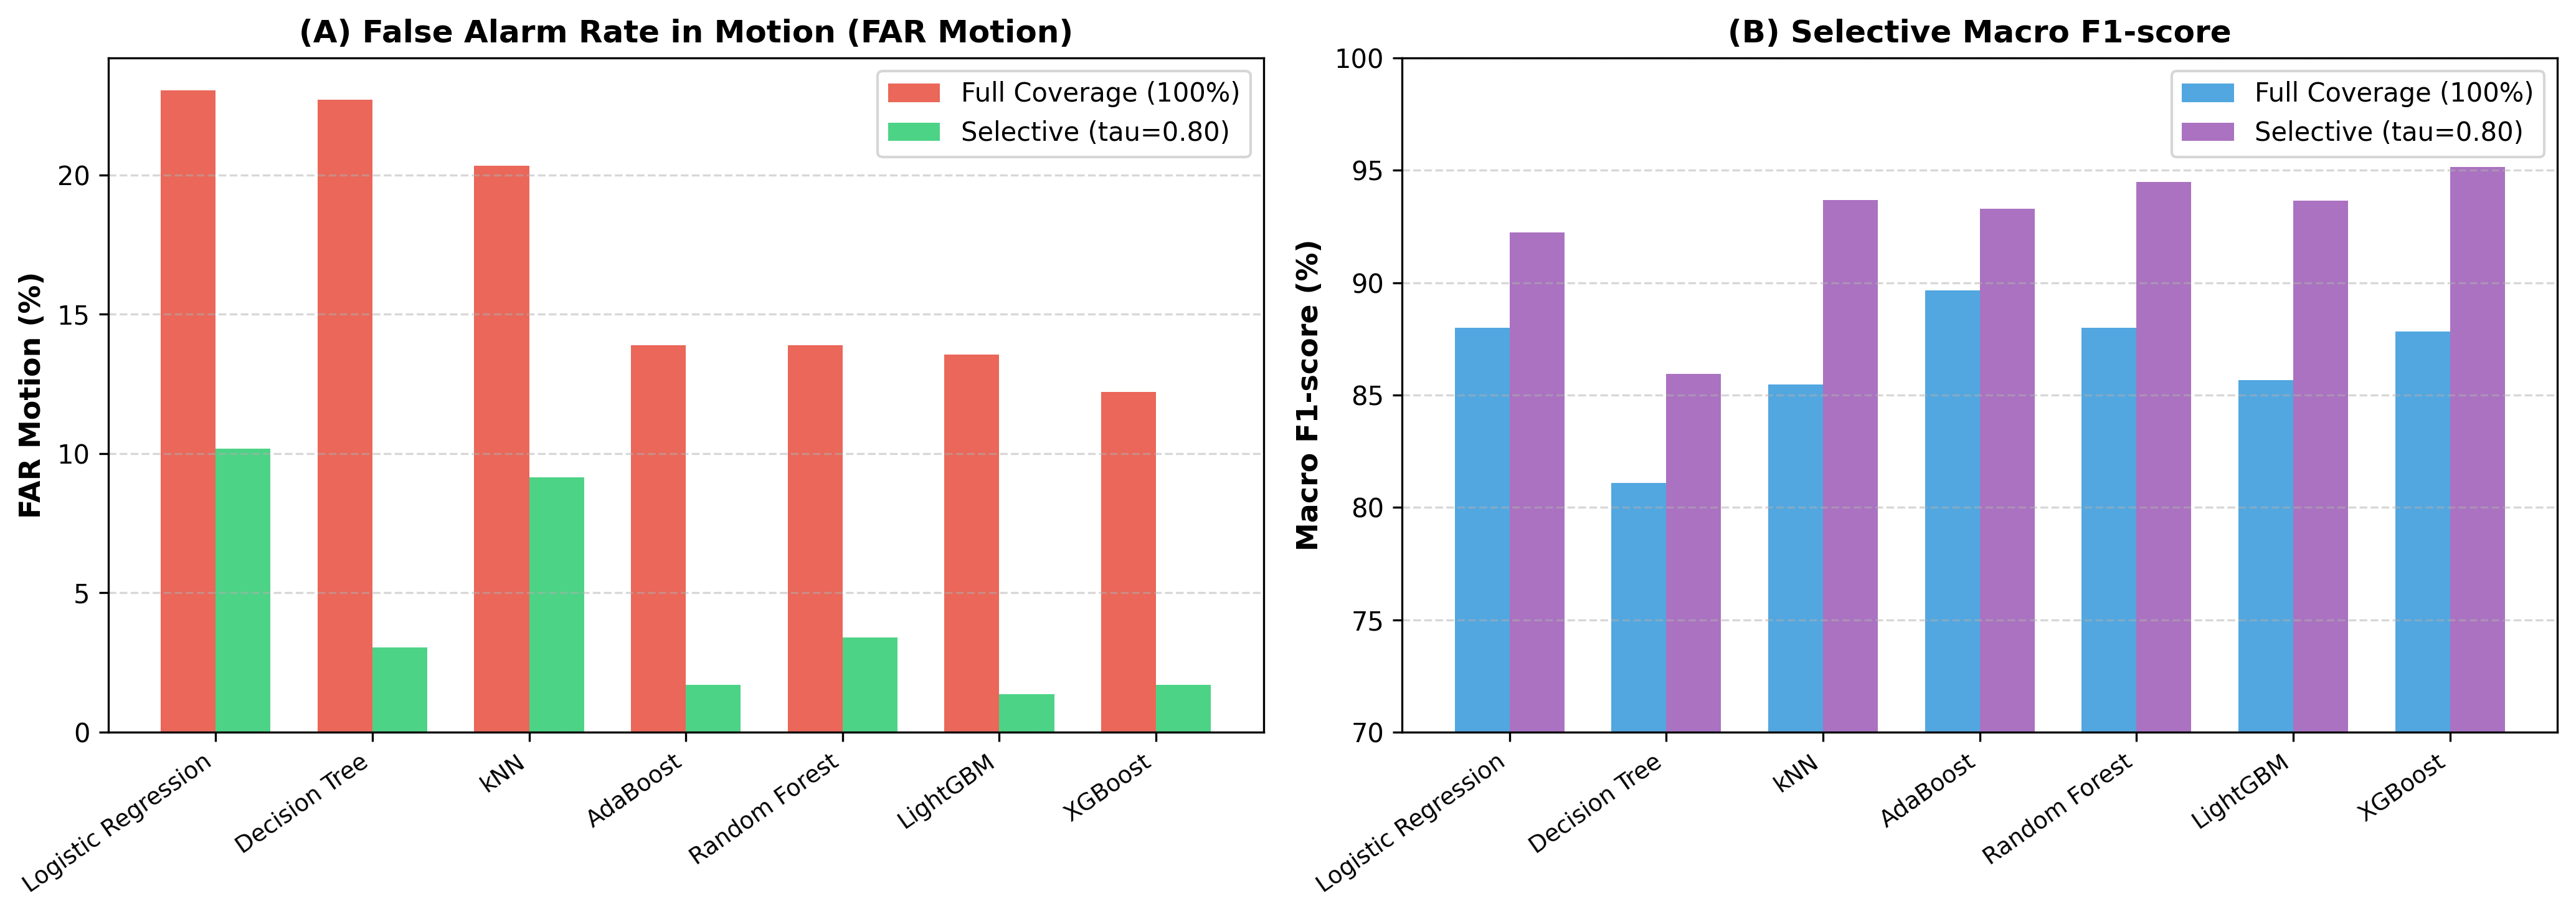

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=300)
models_name = benchmark_df['Model']
x = np.arange(len(models_name))
width = 0.35
# Do thi 1: FAR Motion Reduction
axes[0].bar(x - width/2, benchmark_df['Full_FAR_motion'], width, label='Full Coverage (100%)', color='#e74c3c', alpha=0.85)
axes[0].bar(x + width/2, benchmark_df['Selective_FAR_motion'], width, label='Selective (tau=0.80)', color='#2ecc71', alpha=0.85)
axes[0].set_ylabel('FAR Motion (%)', fontsize=11, fontweight='bold')
axes[0].set_title('(A) False Alarm Rate in Motion (FAR Motion)', fontsize=12, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models_name, rotation=35, ha='right', fontsize=9)
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
# Do thi 2: Macro F1-score Improvement
axes[1].bar(x - width/2, benchmark_df['Full_Macro_F1'], width, label='Full Coverage (100%)', color='#3498db', alpha=0.85)
axes[1].bar(x + width/2, benchmark_df['Selective_Macro_F1'], width, label='Selective (tau=0.80)', color='#9b59b6', alpha=0.85)
axes[1].set_ylabel('Macro F1-score (%)', fontsize=11, fontweight='bold')
axes[1].set_title('(B) Selective Macro F1-score', fontsize=12, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(models_name, rotation=35, ha='right', fontsize=9)
axes[1].set_ylim([70, 100])
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("fig_multimodel_benchmark.png", bbox_inches='tight')
# # plt.show()
print("[+] Da luu bieu do vao fig_multimodel_benchmark.png")


### 7. KIỂM ĐỊNH Ý NGHĨA THỐNG KÊ (WILCOXON SIGNED-RANK TEST)
Kiểm định giả thuyết phi tham số so sánh từng cặp trên 15 đối tượng kiểm thử LOSO:
- Kiểm tra tính vượt trội của XGBoost so với các Baseline kinh điển.
- Kiểm tra tính vượt trội của cơ chế Chọn lọc (Selective) so với mô hình gốc (Full Coverage).


In [8]:
per_subject_xgb_full = []
per_subject_xgb_sel = []

for sid in subjects_list:
    mask = (groups == sid)
    y_sub = y[mask]
    
    # Full XGBoost
    p_sub = oof_raw_probs['XGBoost'][mask]
    pred_sub = (p_sub >= 0.5).astype(int)
    f1_f = f1_score(y_sub, pred_sub, average='macro', zero_division=0)
    per_subject_xgb_full.append(f1_f)
    
    # Selective tau=0.80
    p_cal_sub = oof_cal_probs['XGBoost'][mask]
    acc_sub = (p_cal_sub >= 0.8) | ((1.0 - p_cal_sub) >= 0.8)
    if acc_sub.sum() > 0:
        pred_s = (p_cal_sub >= 0.8).astype(int)
        f1_s = f1_score(y_sub[acc_sub], pred_s[acc_sub], average='macro', zero_division=0)
    else:
        f1_s = f1_f
    per_subject_xgb_sel.append(f1_s)

stat, p_val = wilcoxon(per_subject_xgb_full, per_subject_xgb_sel)
print(f"[*] Wilcoxon Test (XGBoost Full vs Selective tau=0.80): Statistic = {stat}, p-value = {p_val:.5f}")
if p_val < 0.05:
    print("===> Su cai thien co y nghia thong ke ro ret (p < 0.05) tren 15 doi tuong!")


[*] Wilcoxon Test (XGBoost Full vs Selective tau=0.80): Statistic = 23.0, p-value = 0.11585
